# Fiedler VectorとSpectral Clustering

## 概要

グラフのつながりを使ってデータを分割する方法を扱う。Fiedlerベクトルが現れる理由を数式で確認し、4頂点の計算からSpectral Clusteringへ進む。最後に半月形データを分割し、通常のK-meansと比較する。

## 実行環境

カーネルは `wa-src(3.14.6)`、Pythonは3.14.6である。ライブラリの版は下の出力に記録する。セルを上から順に実行すると、作業ディレクトリの `102_nb_files` にSVGを保存する。数値の表示は有効数字3桁とし、計算には丸める前の値を使う。

In [1]:
import platform
from importlib.metadata import version
from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from IPython.display import Latex, display
from matplotlib.ticker import FuncFormatter
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.linalg import eigh
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.datasets import make_moons
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import kneighbors_graph

%matplotlib inline
set_matplotlib_formats('svg')

print('環境: wa-src(3.14.6)')
print('Python:', platform.python_version())
print('OS:', platform.system(), platform.release())
assert platform.python_version() == '3.14.6'
for package in ('numpy', 'scipy', 'matplotlib', 'networkx', 'scikit-learn'):
    print(f'{package}: {version(package)}')

OUT = Path('102_nb_files')
OUT.mkdir(exist_ok=True)
COLORS = np.array(['#2369a1', '#cf5b32'])


def sig3(value):
    """表示だけを有効数字3桁にする。末尾のゼロも残す。"""
    return '0' if value == 0 else format(float(value), '#.3g')


np.set_printoptions(formatter={'float_kind': sig3})
plt.rcParams.update({'font.size': 11, 'svg.fonttype': 'none'})


def save_figure(fig, name):
    """目盛を整え、同じ図をSVG保存とNotebook表示に使う。"""
    for ax in fig.axes:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: sig3(value)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: sig3(value)))
    fig.savefig(OUT / name, format='svg', bbox_inches='tight')
    plt.show()
    plt.close(fig)

環境: wa-src(3.14.6)
Python: 3.14.6
OS: Darwin 25.5.0
numpy: 2.5.4
scipy: 1.18.1
matplotlib: 3.11.2
networkx: 3.7
scikit-learn: 1.9.1


## 1. グラフラプラシアン

自己辺のない無向グラフを考える。重み行列$\mathbf{W}$は対称で、$w_{ij}\geq0$である。次数$d_i$は辺の重みの和であり、次数行列$\mathbf{D}$とラプラシアン$\mathbf{L}$を定める。

<div>
$$
d_i=\sum_jw_{ij},\quad \mathbf{D}=\operatorname{diag}(d_1,\ldots,d_n),\quad \mathbf{L}=\mathbf{D}-\mathbf{W}
$$
</div>

実ベクトル$\mathbf{x}$に対し、対称性から次のように変形できる。

$$
\begin{aligned}
\mathbf{x}^{\mathsf T}\mathbf{L}\mathbf{x}
&=\sum_i d_i x_i^2-\sum_{i,j}w_{ij}x_ix_j\\
&=\frac12\sum_{i,j}w_{ij}x_i^2+\frac12\sum_{i,j}w_{ij}x_j^2-\sum_{i,j}w_{ij}x_ix_j\\
&=\frac12\sum_{i,j}w_{ij}(x_i-x_j)^2
=\sum_{i<j}w_{ij}(x_i-x_j)^2\geq0.
\end{aligned}
$$

重い辺で結ばれた頂点ほど、値の差を大きくするとこの量が増える。また、各行の和は$d_i-\sum_jw_{ij}=0$なので、$\mathbf{L}\mathbf{1}=\mathbf{0}$である。

## 2. Fiedlerベクトル

固有値を$0=\lambda_1\leq\lambda_2\leq\cdots\leq\lambda_n$と並べる。連結なら$\lambda_2>0$であり、対応する単位固有ベクトル$\mathbf{v}_2$がFiedlerベクトルである。直交規格化した固有ベクトルを$\mathbf{v}_j$、$\mathbf{v}_1=\mathbf{1}/\sqrt n$とする。

$$
\begin{aligned}
\mathbf{x}&=\sum_{j=1}^n a_j\mathbf{v}_j,\\
\mathbf{x}^{\mathsf T}\mathbf{1}=0&\Rightarrow a_1=0,\qquad
\mathbf{x}^{\mathsf T}\mathbf{x}=1\Rightarrow\sum_{j=2}^n a_j^2=1,\\
\mathbf{x}^{\mathsf T}\mathbf{L}\mathbf{x}
&=\sum_{j=2}^n\lambda_j a_j^2
\geq\lambda_2\sum_{j=2}^n a_j^2=\lambda_2.
\end{aligned}
$$

$\mathbf{x}=\mathbf{v}_2$で等号が成立する。つまり、定数ベクトルと直交する範囲で、辺の両端の値が最も変わりにくい方向を求めている。

<div>
$$
\mathbf{v}_2\in\operatorname*{arg\,min}_{\mathbf{x}^{\mathsf T}\mathbf{1}=0,\;\mathbf{x}^{\mathsf T}\mathbf{x}=1}\mathbf{x}^{\mathsf T}\mathbf{L}\mathbf{x}
$$
</div>

### グラフ分割との関係

頂点集合を$A,B$に分け、$a=|A|$、$b=|B|$、$n=a+b$とする。境界の重みは$c=\sum_{i\in A,j\in B}w_{ij}$である。$i\in A$なら$f_i=\sqrt{b/a}$、$i\in B$なら$f_i=-\sqrt{a/b}$と置くと、

$$
\begin{aligned}
\mathbf{f}^{\mathsf T}\mathbf{1}&=a\sqrt{b/a}-b\sqrt{a/b}=0,\\
\mathbf{f}^{\mathsf T}\mathbf{f}&=a(b/a)+b(a/b)=n,\\
\mathbf{f}^{\mathsf T}\mathbf{L}\mathbf{f}
&=c\left(\sqrt{b/a}+\sqrt{a/b}\right)^2
=c\frac{(a+b)^2}{ab},\\
\frac{\mathbf{f}^{\mathsf T}\mathbf{L}\mathbf{f}}{\mathbf{f}^{\mathsf T}\mathbf{f}}
&=c\frac{a+b}{ab}=c\left(\frac1a+\frac1b\right)
=\operatorname{RatioCut}(A,B).
\end{aligned}
$$

二値という制約を外した最小化が、先ほどの固有値問題になる。符号による分割は離散的な解に戻す一例であり、RatioCutの最適解を必ず与えるわけではない。

## 3. 4頂点で計算する

辺$(1,2)$と$(3,4)$の重みを1、中央の辺$(2,3)$を$0.200$にする。次数ベクトルは$\mathbf{d}=(1,1.20,1.20,1)^{\mathsf T}$である。行列と固有対を出力し、数値誤差も確認する。

In [2]:
def path_laplacian(weight):
    # 2本の強い辺を、中央の弱い辺でつなぐ。
    W = np.array([
        [0, 1, 0, 0],
        [1, 0, weight, 0],
        [0, weight, 0, 1],
        [0, 0, 1, 0],
    ], dtype=float)
    return W, np.diag(W.sum(axis=1)) - W


W, L = path_laplacian(0.200)
values, vectors = eigh(L)  # 対称行列用。固有値は昇順、固有ベクトルは列。
fiedler = vectors[:, 1].copy()
if fiedler[0] > 0:
    fiedler *= -1  # 図を比較しやすくするために符号をそろえる。
labels = (fiedler >= 0).astype(int)

rows = [' & '.join(sig3(x) for x in row) for row in L]
display(Latex(r'$$\mathbf{L}=\begin{bmatrix}'
              + r'\\'.join(rows) + r'\end{bmatrix}$$'))
pprint({'固有値': values, 'Fiedlerベクトル': fiedler, 'ラベル': labels})

residual = np.linalg.norm(L @ fiedler - values[1] * fiedler)
pprint({'固有対の残差': sig3(residual),
        '直交条件の誤差': sig3(abs(fiedler.sum()))})
assert residual < 1e-12
assert abs(fiedler.sum()) < 1e-12
assert np.array_equal(labels, [0, 0, 1, 1])

# 連続緩和の最小値と、符号で分けた場合のRatioCutを比較する。
A, B = labels == 0, labels == 1
cut = W[np.ix_(A, B)].sum()
ratio_cut = cut * (1 / A.sum() + 1 / B.sum())
display(Latex(r'$$\lambda_2\approx ' + sig3(values[1])
              + r'\leq\operatorname{RatioCut}(A,B)=' + sig3(ratio_cut) + r'$$'))
assert values[1] <= ratio_cut + 1e-12

<IPython.core.display.Latex object>

{'Fiedlerベクトル': array([-0.547, -0.448, 0.448, 0.547]),
 'ラベル': array([0, 0, 1, 1]),
 '固有値': array([8.88e-16, 0.180, 2.00, 2.22])}
{'固有対の残差': '4.10e-16', '直交条件の誤差': '1.67e-15'}


<IPython.core.display.Latex object>

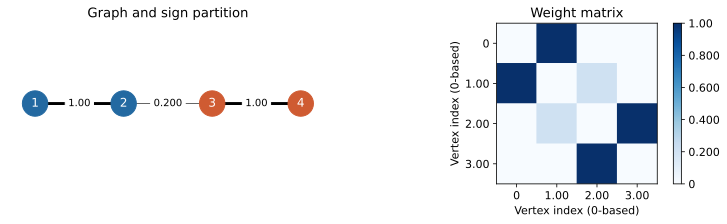

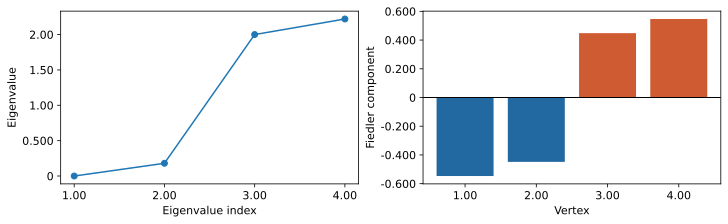

In [3]:
graph = nx.from_numpy_array(W)
positions = {i: (i, 0) for i in range(4)}
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout='constrained')
nx.draw_networkx(
    graph, pos=positions, ax=axes[0], labels={i: i + 1 for i in range(4)},
    node_color=COLORS[labels], font_color='white', node_size=650,
    width=[3 * graph[u][v]['weight'] for u, v in graph.edges],
)
nx.draw_networkx_edge_labels(
    graph, pos=positions, ax=axes[0],
    edge_labels={(u, v): sig3(data['weight']) for u, v, data in graph.edges(data=True)},
)
axes[0].set_title('Graph and sign partition')
axes[0].set_axis_off()
heatmap = axes[1].imshow(W, cmap='Blues', vmin=0, vmax=1)
axes[1].set(xticks=range(4), yticks=range(4), xlabel='Vertex index (0-based)',
            ylabel='Vertex index (0-based)', title='Weight matrix')
fig.colorbar(heatmap, ax=axes[1])
save_figure(fig, '01_graph.svg')

fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout='constrained')
axes[0].plot(range(1, 5), np.maximum(values, 0), 'o-')
axes[0].set(xlabel='Eigenvalue index', ylabel='Eigenvalue', xticks=range(1, 5))
axes[1].bar(range(1, 5), fiedler, color=COLORS[labels])
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set(xlabel='Vertex', ylabel='Fiedler component', xticks=range(1, 5))
save_figure(fig, '02_eigenpairs.svg')

符号が中央の辺で変わり、$\{1,2\}$と$\{3,4\}$に分かれる。私は、行列の数字だけを見るより、この値の並びを確認する方が分割を理解しやすいと感じる。

中央の重みも変えてみる。$\lambda_2$は連結の強さを表す指標であり、中央の重みが0に近づくと0に近づく。固有ベクトル全体の符号には意味がなく、反転しても分割は同じである。

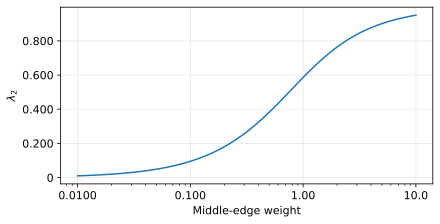

In [4]:
bridge_weights = np.geomspace(0.0100, 10, 80)
second_values = np.array([
    eigh(path_laplacian(weight)[1], eigvals_only=True)[1]
    for weight in bridge_weights
])
fig, ax = plt.subplots(figsize=(6, 3), layout='constrained')
ax.semilogx(bridge_weights, second_values)
ax.set(xlabel='Middle-edge weight', ylabel=r'$\lambda_2$')
ax.grid(alpha=0.300)
save_figure(fig, '03_bridge_weight.svg')

## 4. 正規化してSpectral Clusteringへ進む

次数の差を考慮するには、頂点数の代わりに$\operatorname{vol}(A)=\sum_{i\in A}d_i$を用いる。対応する目的は$\operatorname{Ncut}(A,B)=c/\operatorname{vol}(A)+c/\operatorname{vol}(B)$である。

$d_i>0$として正規化ラプラシアンを定義する。

<div>
$$
\mathbf{L}_{\mathrm{sym}}=\mathbf{D}^{-1/2}\mathbf{L}\mathbf{D}^{-1/2}=\mathbf{I}-\mathbf{D}^{-1/2}\mathbf{W}\mathbf{D}^{-1/2}
$$
</div>

固有ベクトル$\mathbf{u}$から$\mathbf{f}=\mathbf{D}^{-1/2}\mathbf{u}$へ戻すと、

$$
\begin{aligned}
\mathbf{D}^{-1/2}\mathbf{L}\mathbf{D}^{-1/2}\mathbf{u}&=\lambda\mathbf{u},\\
\mathbf{L}\mathbf{D}^{-1/2}\mathbf{u}&=\lambda\mathbf{D}^{1/2}\mathbf{u},\\
\mathbf{L}\mathbf{f}&=\lambda\mathbf{D}\mathbf{f}.
\end{aligned}
$$

この一般化固有値問題はNcutの連続緩和に対応する。小さい方から$k$本を並べた$\mathbf{F}=(\mathbf{f}_1,\ldots,\mathbf{f}_k)$の各行をK-meansに渡す。零固有値の列も含める。これは正規化法の一つであり、非正規化の$\mathbf{v}_2$とは区別する。

## 5. 半月形データの分割

240点を生成し、各点の8近傍を結ぶ。片方向でも近傍なら辺を張り、$\mathbf{W}=\max(\mathbf{C},\mathbf{C}^{\mathsf T})$で対称化する。正解ラベルは比較だけに使う。ARIはラベル番号の入れ替えに影響されず、完全一致では1となる評価値である。

連結成分数: 1
{'SpectralClusteringのARI': '0.983',
 '実装間のARI': '1.00',
 '明示した固有値計算のARI': '0.983',
 '通常のK-meansのARI': '0.222'}


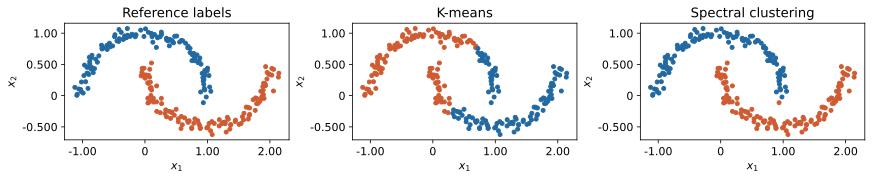

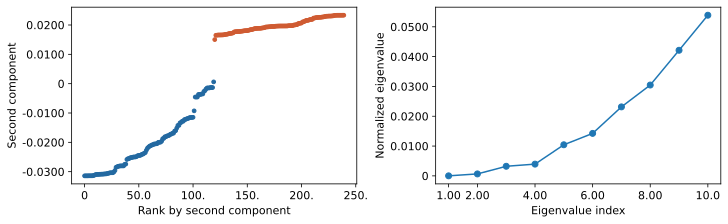

In [5]:
X, truth = make_moons(n_samples=240, noise=0.0600, random_state=102)
C = kneighbors_graph(X, n_neighbors=8, mode='connectivity', include_self=False)
affinity = C.maximum(C.T)
components = connected_components(affinity, directed=False, return_labels=False)
print('連結成分数:', components)
assert components == 1

# 小規模な例なので、正規化ラプラシアンを密行列で明示する。
W_moon = affinity.toarray()
degree = W_moon.sum(axis=1)
assert np.all(degree > 0)
inv_sqrt = 1 / np.sqrt(degree)
L_sym = np.eye(len(X)) - inv_sqrt[:, None] * W_moon * inv_sqrt[None, :]
moon_values, U = eigh(L_sym)
embedding = inv_sqrt[:, None] * U[:, :2]
manual = KMeans(n_clusters=2, n_init=20, random_state=102).fit_predict(embedding)

# 同じ類似度行列をscikit-learnにも渡す。距離行列ではない。
spectral = SpectralClustering(
    n_clusters=2, affinity='precomputed', eigen_solver='arpack',
    assign_labels='kmeans', n_init=20, random_state=102,
).fit_predict(affinity)
ordinary = KMeans(n_clusters=2, n_init=20, random_state=102).fit_predict(X)
pprint({
    '通常のK-meansのARI': sig3(adjusted_rand_score(truth, ordinary)),
    '明示した固有値計算のARI': sig3(adjusted_rand_score(truth, manual)),
    'SpectralClusteringのARI': sig3(adjusted_rand_score(truth, spectral)),
    '実装間のARI': sig3(adjusted_rand_score(manual, spectral)),
})
assert adjusted_rand_score(manual, spectral) > 0.990

fig, axes = plt.subplots(1, 3, figsize=(12, 3), layout='constrained')
for ax, group, title in zip(
    axes, (truth, ordinary, spectral), ('Reference labels', 'K-means', 'Spectral clustering')
):
    ax.scatter(X[:, 0], X[:, 1], c=COLORS[group], s=16)
    ax.set(title=title, xlabel=r'$x_1$', ylabel=r'$x_2$', aspect='equal')
save_figure(fig, '04_moons.svg')

# 一般化固有ベクトルの第2成分と、正規化固有値の並びを見る。
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout='constrained')
order = np.argsort(embedding[:, 1])
axes[0].scatter(np.arange(len(X)), embedding[order, 1],
                c=COLORS[truth[order]], s=14)
axes[0].set(xlabel='Rank by second component', ylabel='Second component')
axes[1].plot(range(1, 11), np.maximum(moon_values[:10], 0), 'o-')
axes[1].set(xlabel='Eigenvalue index', ylabel='Normalized eigenvalue', xticks=[1, 2, 4, 6, 8, 10])
save_figure(fig, '05_embedding.svg')

この設定ではSpectral Clusteringの方が半月形に沿う。ただし、結果は近傍数やノイズに依存する。近傍数が少なすぎるとグラフが切れ、多すぎると異なる群の間にも辺が増える。

非連結グラフでは零固有値が複数あり、単独の第2固有ベクトルだけで分割を決めるのは不安定である。固有値が重複する場合もベクトルは一意でない。大規模データでは密行列化を避け、疎行列の固有値解法を使う。

## 結論

この記事では、FiedlerベクトルをRatioCutの連続緩和から説明し、正規化ラプラシアンによるSpectral Clusteringを実装した。

固有ベクトルはグラフ上の頂点を数値で表す。分割結果を確認する際は、固有値だけでなく、類似度の定義と連結成分数も見る必要がある。

参考文献：U. von Luxburg, [A Tutorial on Spectral Clustering](https://arxiv.org/abs/0711.0189), 2007（第3〜5節）。実装の仕様は[SciPy eigh](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.eigh.html)と[scikit-learn SpectralClustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.SpectralClustering.html)を参照した。